# 06 · Addendum: Mistral Timestral

[Timestral](https://mistral.ai/news/timestral/) is a family of time-series foundation models Mistral released on 15 October 2026, after notebooks 01–04 were run. Mistral reports that its largest model (209 M parameters) ranks first on the GIFT-Eval, TIME and fev-bench benchmarks and beats TimesFM 3.0, the foundation model tested here. Its weights are free to use, commercially included, for companies below $20 M of monthly revenue (a modified MIT licence), where TimesFM 3.0's licence is non-commercial.

This notebook checks the claim on this project's own tests: the same decision points, scores and paired intervals as 01–03, with Timestral added and every other result read from the committed files of those notebooks. Notebooks 01–04 are left as they were run.

**The caveat that governs every real-asset result below:** Timestral was released after the last observation scored here (30 September 2026) and its training data is not disclosed, so recall of the test period cannot be ruled out. The before-and-after-release control of 02 and 03 is impossible. Only the synthetic series of 01, generated for this project, are free of it.

Sections: model · synthetic series (01) · real assets (02) · enrichment (03) · where the gain comes from · conclusions.

## Setup

In [1]:
import os
from functools import partial
from importlib.metadata import version
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

from sbench import plots, tsfm
from sbench.backtest import decision_points, load_results, run_forecast_backtest
from sbench.context import NewsFeed, SearchInterest, covariates
from sbench.data import GOOGLE_TRENDS_DAY, Series, cached, truncate
from sbench.panel import ASSET_CLASS, load_panel
from sbench.scoring import per_forecast, skill_table
from sbench.synthetic import JumpDiffusion, MeanReversion, RandomWalk, RegimeVolatility, synthetic_series
from sbench.tsfm import QuantilePredictor, Timestral

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_OFFLINE", "1")   # weights are cached; never re-check the Hub
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SNAPSHOTS = ROOT / "data" / "snapshots"                    # those of 02 and 03; nothing new is downloaded
COMMITTED = ROOT / "data" / "results"                      # results of 01-03, read only
RESULTS = ROOT / "data" / "results" / "06_timestral"       # Timestral's forecasts; resumable; committed
CHARTS = ROOT / "outputs" / "06_timestral"                 # regenerated; not committed

HISTORY_START, SCORE_START, CHECK_START, END = "2023-01-01", "2024-01-01", "2026-03-01", "2026-09-30"   # as in 02, 03
HORIZON, MIN_HISTORY = 5, 100
TIMESTRAL = partial(QuantilePredictor, Timestral(), log_space=True)   # as TimesFM 3.0 in 01-03

plots.use_style()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## Model

The 209 M model, pinned to its Hugging Face revision and the package commit (the package is not on PyPI and its repository has no release tags). It returns 21 quantiles (0.01, 0.05 to 0.95 in steps of 0.05, 0.99), mapped onto the threshold grid exactly as TimesFM's deciles are; like TimesFM, it forecasts log prices from the last 1,024 closes and takes related series, news and search interest as past-only covariates.

In [2]:
from huggingface_hub.constants import HF_HUB_CACHE

model = Timestral()
ref = Path(HF_HUB_CACHE) / f"models--{model.checkpoint.replace('/', '--')}" / "refs" / "main"
display(pd.DataFrame([
    {"item": "weights revision", "expected": model.revision[:12], "found": ref.read_text().strip()[:12]},
    {"item": "timestral package", "expected": "1.0.0", "found": version("timestral")},
]).assign(ok=lambda d: d["expected"] == d["found"]).set_index("item"))

,expected,found,ok
item,,,
weights revision,9874d252ab0a,9874d252ab0a,True
timestral package,1.0.0,1.0.0,True


### Scoring

Each section loads the committed results of its notebook, adds Timestral's forecasts on the same decision points and scores them as there: CRPS skill and Brier skill on P(up) against the random walk, and the same skills of Timestral against TimesFM 3.0 directly. Intervals are 95% paired bootstraps over decision points.

In [3]:
def combine(committed: Path, new: Path, keep: list[str]) -> pd.DataFrame:
    """Per-forecast scores of the `keep` predictors and Timestral, on the decision points both files hold."""
    old, ts = load_results(committed), load_results(new)
    keys = ["series", "t", "horizon"]
    common = ts[keys].drop_duplicates().merge(old[keys].drop_duplicates())
    return per_forecast(pd.concat([old[old["predictor"].isin(keep)], ts], ignore_index=True).merge(common))


def skills(per: pd.DataFrame, baseline: str = "random_walk") -> pd.DataFrame:
    """CRPS and Brier-on-P(up) skill against `baseline`, with the 80% band's coverage."""
    out = []
    for metric, label in (("crps_n", "crps"), ("brier_up", "brier_up")):
        sk = skill_table(per, metric, baseline=baseline).set_index("predictor")
        out.append(sk[["N", "skill", "lo", "hi"]].rename(columns={c: f"{label}_{c}" for c in ("skill", "lo", "hi")}))
    cover = per.groupby("predictor")["in_q10_q90"].mean().rename("cover_80")
    return out[0].join(out[1].drop(columns="N")).join(cover).sort_values("crps_skill", ascending=False)


HEAD_TO_HEAD = []   # Timestral against TimesFM 3.0, per test, for the summary chart


def head_to_head(per: pd.DataFrame, test: str, timesfm: str = "timesfm3", timestral: str = "timestral") -> None:
    for metric in ("crps_n", "brier_up"):
        sk = skill_table(per[per["predictor"].isin([timesfm, timestral])], metric, baseline=timesfm)
        HEAD_TO_HEAD.append({"test": test, "metric": metric, **sk.iloc[0][["skill", "lo", "hi", "N"]].to_dict()})

## Synthetic series (01)

The six scenarios of 01 (420 observations each, seeds 0–5) and its 60 decision points per scenario at horizon 5. The oracle forecasts from the true conditional distribution, so the distance to it is the measure that matters; no model can have seen these series.

In [4]:
SCENARIOS = {   # as in 01
    "random_walk":    RandomWalk(mu=0.0, sigma=0.02),
    "trend_up":       RandomWalk(mu=0.006, sigma=0.015),
    "trend_down":     RandomWalk(mu=-0.006, sigma=0.015),
    "mean_reversion": MeanReversion(phi=0.8, sigma=0.02),
    "vol_regimes":    RegimeVolatility(sigma_calm=0.008, sigma_turbulent=0.04, stay_calm=0.98, stay_turbulent=0.97),
    "jumps":          JumpDiffusion(mu=0.003, sigma=0.008, jump_rate=0.08, jump_mean=-0.05, jump_std=0.03),
}
SYNTHETIC = [synthetic_series(key, proc, n=420, seed=i, description=f"Asset {chr(65 + i)}: daily close price")
             for i, (key, proc) in enumerate(SCENARIOS.items())]
for s in SYNTHETIC:
    run_forecast_backtest(s, [TIMESTRAL(name="timestral")], HORIZON, RESULTS / "01_synthetic.csv",
                          decision_points(s, HORIZON, min_history=MIN_HISTORY, step=HORIZON, max_points=60),
                          verbose=False)

per01 = combine(COMMITTED / "01_synthetic" / "forecasts.csv", RESULTS / "01_synthetic.csv",
                ["oracle", "random_walk", "empirical", "timesfm3", "timesfm2.5"])
display(Markdown(f"**Against the random walk** ({per01['t'].nunique()} dates, {len(per01) // per01['predictor'].nunique()} decision points)"))
display(skills(per01))
display(Markdown("**Against the oracle** (0 = as good as the true distribution)"))
display(skills(per01, baseline="oracle").drop(columns="cover_80"))
head_to_head(per01, "01 synthetic, h5")

**Against the random walk** (60 dates, 360 decision points)

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi,cover_80
predictor,,,,,,,,
oracle,360,0.137,0.093,0.179,0.185,0.117,0.252,0.822
timestral,360,0.128,0.088,0.168,0.164,0.094,0.231,0.808
timesfm3,360,0.110,0.061,0.155,0.157,0.080,0.227,0.792
timesfm2.5,360,0.105,0.065,0.141,0.144,0.084,0.202,0.836
empirical,360,0.093,0.046,0.136,0.136,0.066,0.203,0.781


**Against the oracle** (0 = as good as the true distribution)

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,,,,
timestral,360,-0.011,-0.034,0.013,-0.026,-0.067,0.012
timesfm3,360,-0.032,-0.065,0.001,-0.035,-0.085,0.011
timesfm2.5,360,-0.037,-0.065,-0.008,-0.050,-0.100,-0.004
empirical,360,-0.051,-0.081,-0.023,-0.060,-0.118,-0.003
random_walk,360,-0.159,-0.219,-0.103,-0.228,-0.336,-0.132


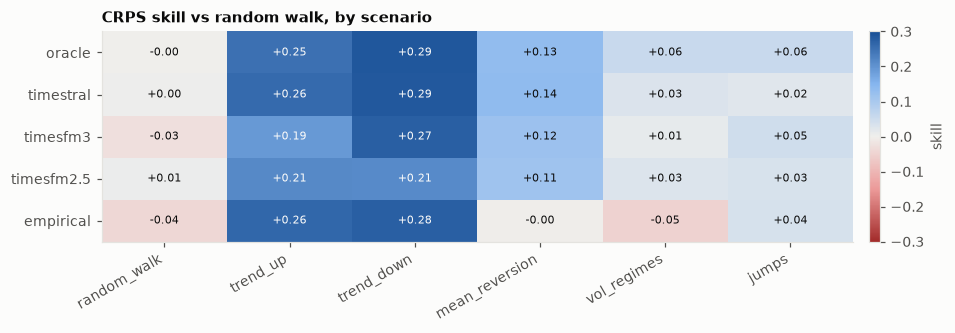

In [5]:
by_sc = skill_table(per01, "crps_n", by=("series",)).pivot(index="predictor", columns="series", values="skill")
order = ["oracle", "timestral", "timesfm3", "timesfm2.5", "empirical"]
plots.heatmap(by_sc.loc[order, list(SCENARIOS)], span=0.3, title="CRPS skill vs random walk, by scenario",
              cbar_label="skill", path=CHARTS / "01_crps_skill_by_scenario.png");

## Real assets (02)

The eight instruments of 02 from its snapshots (FX from Yahoo, as there) and its 1,232 decision points at horizon 5 from January 2024 to September 2026.

In [6]:
SERIES_02 = [Series(key, key, truncate(cached(SNAPSHOTS / "02_real_assets" / f"{key}.csv", None), HISTORY_START, END))
             for key in ASSET_CLASS]
for s in SERIES_02:
    run_forecast_backtest(s, [TIMESTRAL(name="timestral")], HORIZON, RESULTS / "02_real_assets.csv",
                          decision_points(s, HORIZON, min_history=MIN_HISTORY, step=HORIZON, start=SCORE_START),
                          verbose=False)

per02 = combine(COMMITTED / "02_real_assets" / "forecasts.csv", RESULTS / "02_real_assets.csv",
                ["random_walk", "empirical", "timesfm3", "timesfm2.5"])
display(skills(per02))
head_to_head(per02, "02 real assets, h5")

per02["year"] = pd.to_datetime(per02["t"]).dt.year.map(lambda y: f"{y} (to Sep)" if y == 2026 else str(y))
by_year = skill_table(per02, "crps_n", by=("year",))
display(Markdown("**CRPS skill vs random walk by year**"))
display(by_year[by_year["predictor"].isin(["timestral", "timesfm3"])].pivot(
    index="predictor", columns="year", values=["skill", "lo", "hi"]))
display(Markdown("**CRPS skill vs random walk by instrument**"))
skill_table(per02, "crps_n", by=("series",)).pivot(index="predictor", columns="series", values="skill")

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi,cover_80
predictor,,,,,,,,
timestral,1232,0.007,0.001,0.014,-0.005,-0.016,0.005,0.806
timesfm2.5,1232,-0.006,-0.018,0.006,-0.020,-0.036,-0.003,0.805
timesfm3,1232,-0.009,-0.023,0.004,-0.020,-0.039,0.001,0.794
empirical,1232,-0.017,-0.032,-0.001,-0.029,-0.056,-0.004,0.776


**CRPS skill vs random walk by year**

skill                          lo                         hi                    
year        2024   2025 2026 (to Sep)   2024   2025 2026 (to Sep)  2024  2025 2026 (to Sep)
predictor                                                                                  
timesfm3  -0.013 -0.004        -0.010 -0.037 -0.027        -0.033 0.011 0.019         0.011
timestral  0.003  0.014         0.004 -0.007  0.004        -0.012 0.011 0.025         0.018

**CRPS skill vs random walk by instrument**

series,AAPL,BTC,ETH,EURUSD,GLD,SPY,USDJPY,USO
predictor,,,,,,,,
empirical,-0.036,-0.018,-0.003,-0.017,0.028,-0.022,-0.028,-0.043
timesfm2.5,-0.023,-0.000,-0.003,-0.031,0.023,-0.009,-0.006,-0.006
timesfm3,-0.023,-0.030,-0.001,-0.035,-0.008,0.013,0.012,0.003
timestral,0.001,0.009,0.012,-0.008,0.018,0.022,-0.004,0.002


## Enrichment (03)

The panel of 03 (FX from ECB fixings, each close at the time it became known), its decision points at horizon 5 from 2024 and at horizon 1 from March 2026, and its inputs: related series, news coverage and tone, search interest, passed to Timestral as past-only covariates exactly as to TimesFM 3.0. The question is twice whether Timestral beats TimesFM 3.0, and whether the inputs add to Timestral itself.

In [7]:
SERIES_03 = load_panel(SNAPSHOTS)
BY_KEY = {s.key: s for s in SERIES_03}
IDXS = {HORIZON: {s.key: decision_points(s, HORIZON, MIN_HISTORY, HORIZON, start=SCORE_START) for s in SERIES_03},
        1: {s.key: decision_points(s, 1, MIN_HISTORY, 1, start=CHECK_START) for s in SERIES_03}}

RELATED = {   # as in 03
    "BTC": ("ETH", "SPY"), "ETH": ("BTC", "SPY"), "SPY": ("AAPL", "USDJPY"), "AAPL": ("SPY", "USDJPY"),
    "GLD": ("EURUSD", "USDJPY"), "USO": ("SPY", "EURUSD"), "EURUSD": ("USDJPY", "GLD"), "USDJPY": ("EURUSD", "SPY"),
}
NEWS_LABELS = {"BTC": "Bitcoin", "ETH": "Ether", "SPY": "US stocks", "AAPL": "Apple", "GLD": "gold",
               "USO": "oil", "EURUSD": "the euro", "USDJPY": "the yen"}
TRENDS_TERMS = {"BTC": ("btc", 0), "ETH": ("eth", 0), "SPY": ("s&p 500", 0), "AAPL": ("aapl", 0),
                "GLD": ("gold price", 0), "USO": ("crude oil", 0), "EURUSD": ("eur usd", 0), "USDJPY": ("yen", 7)}
FEED = NewsFeed.load(SNAPSHOTS / "03_enrichment" / "news", labels=NEWS_LABELS)
SEARCH = SearchInterest(
    {k: Series(k, f"Google searches for '{term}'", cached(SNAPSHOTS / "03_enrichment" / f"trends_{k}.csv", None),
               kind="covariate", close_time=GOOGLE_TRENDS_DAY) for k, (term, _) in TRENDS_TERMS.items()},
    {k: term + (" (finance category)" if cat else "") for k, (term, cat) in TRENDS_TERMS.items()})
INPUTS = {
    "price": {s.key: () for s in SERIES_03},
    "related": {s.key: tuple(BY_KEY[k] for k in RELATED[s.key]) for s in SERIES_03},
    "news": {s.key: covariates(s, partial(FEED.features, s.key), prefix="news_") for s in SERIES_03},
    "search": {s.key: covariates(s, partial(SEARCH.features, s.key)) for s in SERIES_03},
}
RUNS = {   # results file of 03: (horizon, inputs)
    "price": (HORIZON, "price"), "related": (HORIZON, "related"), "news": (HORIZON, "news"),
    "search": (HORIZON, "search"), "price_h1": (1, "price"), "news_h1": (1, "news"), "search_h1": (1, "search"),
}

for file, (h, variant) in RUNS.items():
    name = "timestral" if variant == "price" else f"timestral+{variant}"
    pred = TIMESTRAL(name=name, use_related=variant != "price")
    for s in SERIES_03:
        run_forecast_backtest(s, [pred], h, RESULTS / f"03_{file}.csv", IDXS[h][s.key],
                              related=INPUTS[variant][s.key], verbose=False)
tsfm.release()

In [8]:
def per_run(file: str) -> pd.DataFrame:
    """Scores of a 03 run, with the price-only predictors of the same horizon on the same points."""
    h, variant = RUNS[file]
    price_file = "price" if h == HORIZON else "price_h1"
    price = combine(COMMITTED / "03_enrichment" / f"{price_file}.csv", RESULTS / f"03_{price_file}.csv",
                    ["random_walk", "timesfm3"])
    if variant == "price":
        return price
    run = combine(COMMITTED / "03_enrichment" / f"{file}.csv", RESULTS / f"03_{file}.csv", [f"timesfm3+{variant}"])
    return pd.concat([price.merge(run[["series", "t"]].drop_duplicates()), run], ignore_index=True)


def versus(per: pd.DataFrame, baseline: str, pred: str, metric: str) -> str:
    s = skill_table(per[per["predictor"].isin([baseline, pred])], metric, baseline=baseline).iloc[0]
    return f"{s['skill']:+.3f} ({s['lo']:+.3f}, {s['hi']:+.3f})"


rows = []
for file, (h, variant) in RUNS.items():
    per, sfx = per_run(file), ("" if variant == "price" else f"+{variant}")
    head_to_head(per, f"03 {variant}, h{h}", timesfm=f"timesfm3{sfx}", timestral=f"timestral{sfx}")
    for metric in ("crps_n", "brier_up"):
        rows.append({"horizon": h, "inputs": variant, "metric": metric, "N": int((per["predictor"] == "random_walk").sum()),
                     "timestral vs RW": versus(per, "random_walk", f"timestral{sfx}", metric),
                     "timesfm3 vs RW": versus(per, "random_walk", f"timesfm3{sfx}", metric),
                     "timestral vs timesfm3": versus(per, f"timesfm3{sfx}", f"timestral{sfx}", metric),
                     "inputs' gain for timestral": versus(per, "timestral", f"timestral{sfx}", metric) if sfx else ""})
pd.DataFrame(rows).set_index(["horizon", "inputs", "metric"]).sort_index(ascending=[False, True, True])

N          timestral vs RW           timesfm3 vs RW    timestral vs timesfm3 inputs' gain for timestral
horizon inputs  metric                                                                                                              
5       news    brier_up  1228  +0.005 (-0.007, +0.017)  -0.018 (-0.037, +0.002)  +0.022 (+0.009, +0.036)    -0.000 (-0.003, +0.002)
                crps_n    1228  +0.009 (+0.002, +0.016)  -0.011 (-0.024, +0.002)  +0.019 (+0.010, +0.029)    -0.000 (-0.002, +0.001)
        price   brier_up  1228  +0.005 (-0.007, +0.017)  -0.016 (-0.038, +0.004)  +0.021 (+0.005, +0.037)                           
                crps_n    1228  +0.009 (+0.002, +0.016)  -0.010 (-0.024, +0.003)  +0.019 (+0.008, +0.030)                           
        related brier_up  1228  +0.008 (-0.004, +0.019)  -0.010 (-0.030, +0.009)  +0.017 (+0.004, +0.031)    +0.003 (-0.004, +0.010)
                crps_n    1228  +0.011 (+0.004, +0.017)  -0.007 (-0.020, +0.005)  +0.018 (+0.009, +0.026)    +0.001 (-0.003, +0.005)
        search  brier_up  1228  +0.001 (-0.011, +0.014)  -0.013 (-0.033, +0.006)  +0.014 (+0.000, +0.028)    -0.004 (-0.008, +0.000)
                crps_n    1228  +0.007 (-0.001, +0.014)  -0.011 (-0.024, +0.002)  +0.018 (+0.008, +0.026)    -0.002 (-0.005, +0.000)
1       news    brier_up  1312  -0.001 (-0.012, +0.010)  -0.012 (-0.025, +0.001)  +0.011 (-0.001, +0.024)    -0.004 (-0.007, -0.000)
                crps_n    1312  +0.005 (-0.002, +0.012)  -0.003 (-0.013, +0.007)  +0.008 (+0.000, +0.016)    -0.003 (-0.005, -0.001)
        price   brier_up  1312  +0.003 (-0.009, +0.014)  -0.016 (-0.030, -0.003)  +0.019 (+0.005, +0.033)                           
                crps_n    1312  +0.008 (+0.001, +0.015)  -0.005 (-0.016, +0.005)  +0.013 (+0.005, +0.022)                           
        search  brier_up  1312  +0.002 (-0.010, +0.013)  -0.018 (-0.032, -0.004)  +0.019 (+0.005, +0.032)    -0.001 (-0.006, +0.004)
                crps_n    1312  +0.008 (-0.000, +0.015)  -0.002 (-0.012, +0.007)  +0.010 (+0.001, +0.018)    -0.001 (-0.004, +0.002)

## Where the gain comes from

CRPS rewards both the centre of a forecast distribution and its spread; Brier on P(up) only the side of the centre. The table below separates them on 02's decision points: how far each model's median moves away from the last close (any move is a directional bet), how wide its 80% band is, and how well that width ranks the size of the coming move within each instrument (the volatility forecast).

In [9]:
d = per02[per02["predictor"].isin(["random_walk", "timesfm3", "timestral"])].copy()
d["drift"] = (d["q50"] / d["current"] - 1).abs()
d["width"] = (d["q90"] - d["q10"]) / d["current"]
d["move"] = (d["future"] / d["current"] - 1).abs()


def width_rank_corr(g: pd.DataFrame) -> float:
    return g.groupby("series").apply(lambda x: x["width"].rank().corr(x["move"].rank()), include_groups=False).mean()


centre_spread = pd.DataFrame({
    "|median - last close|, median %": d.groupby("predictor")["drift"].median() * 100,
    "80% band width, median %": d.groupby("predictor")["width"].median() * 100,
    "rank corr(band width, |move|), within instrument": d.groupby("predictor").apply(width_rank_corr, include_groups=False),
    "cover_80": d.groupby("predictor")["in_q10_q90"].mean(),
}).loc[["random_walk", "timesfm3", "timestral"]]
centre_spread

,"|median - last close|, median %","80% band width, median %","rank corr(band width, |move|), within instrument",cover_80
predictor,,,,
random_walk,0.000,8.608,0.116,0.800
timesfm3,0.434,8.818,0.140,0.794
timestral,0.132,8.508,0.149,0.806


## Summary: Timestral against TimesFM 3.0

Skill of Timestral with TimesFM 3.0 as the baseline, on every test above (each pair with the same inputs).

skill     lo    hi     N
test               metric                                  
01 synthetic, h5   CRPS            0.020 -0.009 0.049   360
                   Brier on P(up)  0.009 -0.036 0.052   360
02 real assets, h5 CRPS            0.016  0.006 0.027  1232
                   Brier on P(up)  0.014 -0.002 0.030  1232
03 price, h5       CRPS            0.019  0.008 0.030  1228
                   Brier on P(up)  0.021  0.005 0.037  1228
03 related, h5     CRPS            0.018  0.009 0.026  1228
                   Brier on P(up)  0.017  0.004 0.031  1228
03 news, h5        CRPS            0.019  0.010 0.029  1228
                   Brier on P(up)  0.022  0.009 0.036  1228
03 search, h5      CRPS            0.018  0.008 0.026  1228
                   Brier on P(up)  0.014  0.000 0.028  1228
03 price, h1       CRPS            0.013  0.005 0.022  1312
                   Brier on P(up)  0.019  0.005 0.033  1312
03 news, h1        CRPS            0.008  0.000 0.016  1312
                   Brier on P(up)  0.011 -0.001 0.024  1312
03 search, h1      CRPS            0.010  0.001 0.018  1312
                   Brier on P(up)  0.019  0.005 0.032  1312

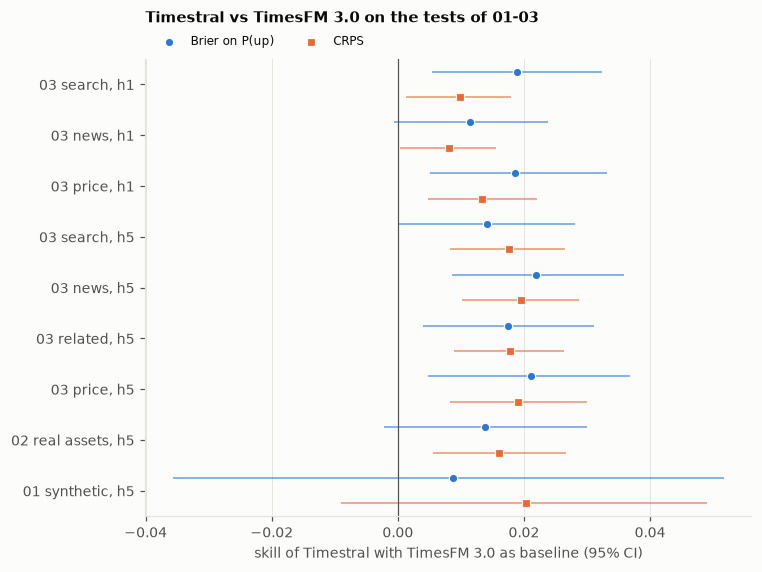

In [10]:
h2h = pd.DataFrame(HEAD_TO_HEAD)
h2h["metric"] = h2h["metric"].map({"crps_n": "CRPS", "brier_up": "Brier on P(up)"})
fig = plots.dot_plot(h2h.iloc[::-1], y="test", x="skill", hue="metric", lo="lo", hi="hi",
                     xlabel="skill of Timestral with TimesFM 3.0 as baseline (95% CI)",
                     title="Timestral vs TimesFM 3.0 on the tests of 01-03")
fig.savefig(CHARTS / "02_timestral_vs_timesfm3.png")
h2h.set_index(["test", "metric"])

## Conclusions

- **Mistral's claim holds on this project's tests.** Timestral beats TimesFM 3.0 on CRPS in all eight comparisons on real assets, each interval above zero (+0.008 to +0.019), and on the synthetic series it comes closest to the oracle (−0.011 against it, TimesFM 3.0 −0.032). There its lead over TimesFM 3.0 is not significant (+0.020, −0.009 to +0.049) and not uniform: it is ahead on trends and mean reversion, behind on jumps and volatility regimes.
- **It is the first predictor in this project whose CRPS interval against the random walk lies above zero on real assets**: +0.007 (+0.001 to +0.014) in 02, +0.007 to +0.011 at horizon 5 in 03, positive in each year. The effect is under 1% of the score.
- **It has no directional signal.** Brier skill on P(up) against the random walk is −0.005 (−0.016 to +0.005) in 02, and its interval spans zero in every run of 03. Its edge over the random walk is in the spread: its 80% band ranks the size of the coming move better (rank correlation 0.149 within instrument, against 0.116). Its edge over TimesFM 3.0 is mostly in the centre: its median stays near the last close (0.13% away, against 0.43%), so it pays less for directional bets that do not pay off.
- **Related series, news and search add nothing**, as for TimesFM 3.0: they change its CRPS skill by −0.003 to +0.001, and news at horizon 1 lowers it slightly (−0.003, −0.005 to −0.001).
- **The real-asset results are in-sample for Timestral.** It was released after the period scored here, with undisclosed training data, so recall cannot be ruled out; only the synthetic series are free of it, and there the comparison with TimesFM 3.0 is inconclusive. A period after its release is the clean test.

For the project's bottom line: no model forecasts direction, and that stands. A newer foundation model forecasts the distribution of the next move slightly better than the random walk, through its spread, which makes it a question of volatility forecasting rather than of trading signals.